<a href="https://colab.research.google.com/github/LennardBehmann/Intro-ML/blob/main/Homework_5/ML_HW5_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW5 - Problem 2

In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
url = "https://raw.githubusercontent.com/LennardBehmann/Intro-ML/refs/heads/main/Homework_5/Housing.csv"

df = pd.read_csv(url)

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


2.1 X and y

In [3]:
features=['area','bedrooms', 'bathrooms', 'stories', 'parking']
X=df[features]
y=df['price']
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (545, 5)
y shape: (545,)


2.2 80/20 split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (436, 5)
X_test shape: (109, 5)
y_train shape: (436,)
y_test shape: (109,)


2.3 Standardise

In [5]:
# Standardize input features X
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)


# Standardize target values y
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

2.4 Tensor convertion

In [6]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
#add .flatten() to change size to vector
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32).flatten()
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).flatten()

print(X_train_tensor.shape)
print(y_train_tensor.shape)
print(X_test_tensor.shape)
print(y_test_tensor.shape)

torch.Size([436, 5])
torch.Size([436])
torch.Size([109, 5])
torch.Size([109])


2.5 define model

In [7]:
# X is the 5 features
# w is a tensor with the 5 weights for w1 to w5
def model_housing5(X, w, b):
    return X @ w + b

w = torch.zeros(5, requires_grad=True)
b = torch.zeros((), requires_grad=True)

y_pred = model_housing5(X_train_tensor, w, b)
print(y_pred.shape)

torch.Size([436])


2.6 define loss

In [8]:
def loss_fn(y_pred, y):
    squared_diffs = (y_pred - y)**2
    return squared_diffs.mean()

loss = loss_fn(y_pred, y_train_tensor)
print("Initial Training Loss:", loss.item())



Initial Training Loss: 1.0


2.6.1 add function for R**2

In [9]:
def summ_sqr(Vector_A, Vector_B):
    Summe = ((Vector_A - Vector_B)**2).sum()
    return Summe

2.7 training

In [10]:

learningrates = [0.1, 0.01, 0.001, 0.0001]

loss_history_training = {}
loss_history_validation = {}
R_sqr_history = {}
trained_params = {}
best_checkpoints = {}

for lr in learningrates:

    print(f"\nTraining mit Learning Rate: {lr}")

    # Initialize parameters
    w = torch.ones(5, requires_grad=True)
    b = torch.zeros((), requires_grad=True)

    optimizer = torch.optim.SGD([w, b], lr=lr)

    # Lists for training results
    loss_values = []
    val_loss_values = []
    R_sqr_list = []

    # Initialize best checkpoint tracking
    best_val_loss = float("inf")
    best_epoch = 0
    best_w = None
    best_b = None
    best_r2 = None

    for epoch in range(1, 5001):

        optimizer.zero_grad()

        # Training: Calculate loss and gradients
        y_pred_train = model_housing5(X_train_tensor, w, b)
        train_loss = loss_fn(y_pred_train, y_train_tensor)

        train_loss.backward()
        optimizer.step()

        # Evaluation with updated parameters
        with torch.no_grad():

            # Training Loss
            train_pred_eval = model_housing5(X_train_tensor, w, b)
            train_loss_eval = loss_fn(train_pred_eval, y_train_tensor)

            # Validation Loss
            val_pred = model_housing5(X_test_tensor, w, b)
            val_loss = loss_fn(val_pred, y_test_tensor)

            # Validation R²
            SS_res = summ_sqr(y_test_tensor, val_pred)
            SS_tot = summ_sqr(y_test_tensor, y_test_tensor.mean())
            R_sqr = 1 - (SS_res / SS_tot)

        # Save results for every epoch
        loss_values.append(train_loss_eval.item())
        val_loss_values.append(val_loss.item())
        R_sqr_list.append(R_sqr.item())

        # Save best checkpoint
        if val_loss.item() < best_val_loss:
            best_val_loss = val_loss.item()
            best_epoch = epoch
            best_w = w.detach().clone()
            best_b = b.detach().clone()
            best_r2 = R_sqr.item()

        # Print results every 500 epochs
        if epoch % 500 == 0:
            print(
                f"Epoch {epoch}: "
                f"Train Loss = {train_loss_eval.item():.6f}, "
                f"Val Loss = {val_loss.item():.6f}, "
                f"Val R² = {R_sqr.item():.4f}"
            )

    # Save final results for each learning rate
    loss_history_training[lr] = loss_values
    loss_history_validation[lr] = val_loss_values
    R_sqr_history[lr] = R_sqr_list

    trained_params[lr] = (w.detach().tolist(), b.item())

    # Save best checkpoint for each learning rate
    best_checkpoints[lr] = {
        "epoch": best_epoch,
        "val_loss": best_val_loss,
        "val_r2": best_r2,
        "w": best_w.tolist(),
        "b": best_b.item()
    }

    print(
        f"Best Checkpoint: Epoch {best_epoch}, "
        f"Validation Loss = {best_val_loss:.6f}"
    )



Training mit Learning Rate: 0.1
Epoch 500: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 1000: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 1500: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 2000: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 2500: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 3000: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 3500: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 4000: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 4500: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 5000: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Best Checkpoint: Epoch 5, Validation Loss = 0.704070

Training mit Learning Rate: 0.01
Epoch 500: Train Loss = 0.437832, Val Loss = 0.743520, Val R² = 0.5464
Epoch 1000: Train Loss = 0.437832, Val Loss = 0.743571, Val R² = 0.5464
Epoch 1500: Train 

2.8 plots

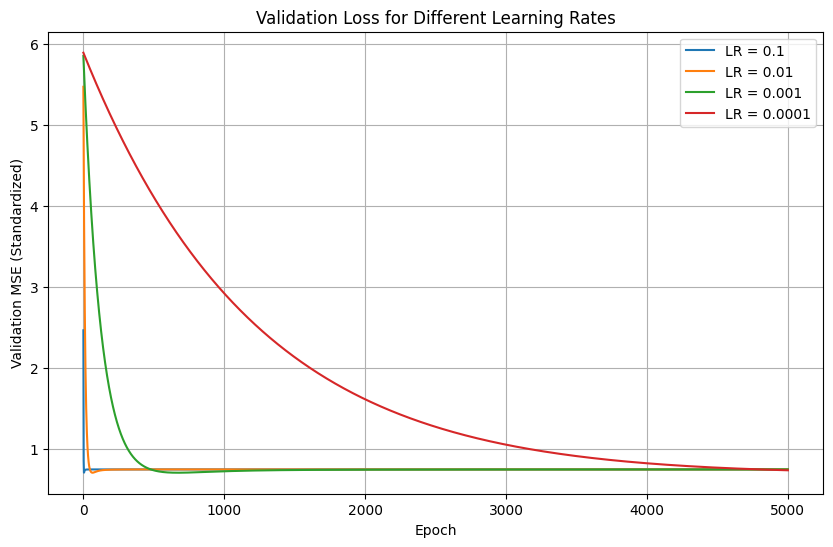

In [11]:
# Plot Validation Loss for all Learning Rates

plt.figure(figsize=(10, 6))

for lr in learningrates:
    plt.plot(
        range(1, len(loss_history_validation[lr]) + 1),
        loss_history_validation[lr],
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MSE (Standardized)")
plt.title("Validation Loss for Different Learning Rates")
plt.legend()
plt.grid(True)

plt.show()

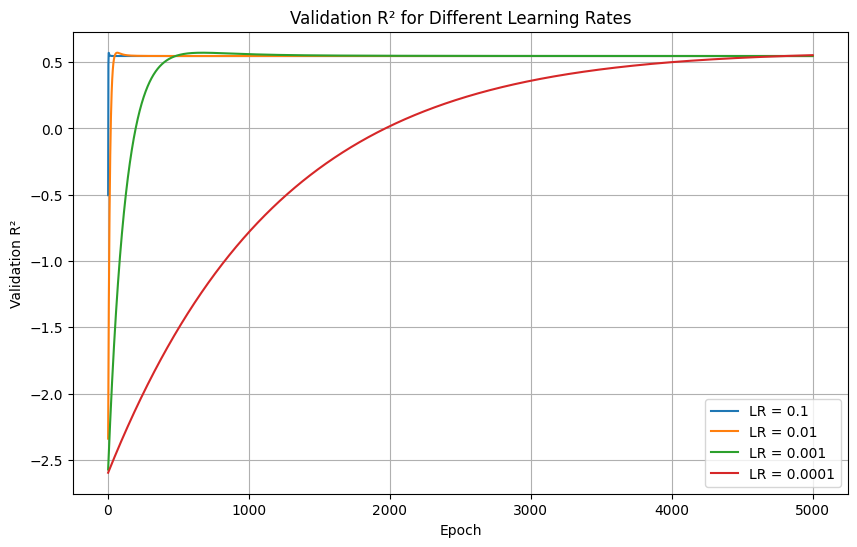

In [12]:
# Plot Validation R² for all Learning Rates

plt.figure(figsize=(10, 6))

for lr in learningrates:
    plt.plot(
        range(1, len(R_sqr_history[lr]) + 1),
        R_sqr_history[lr],
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation R²")
plt.title("Validation R² for Different Learning Rates")
plt.legend()
plt.grid(True)

plt.show()

Best Learning Rate: 0.0001
Final Training Loss: 0.5717989206314087
Final Validation Loss: 0.7329183220863342
Final Validation R²: 0.5529046058654785


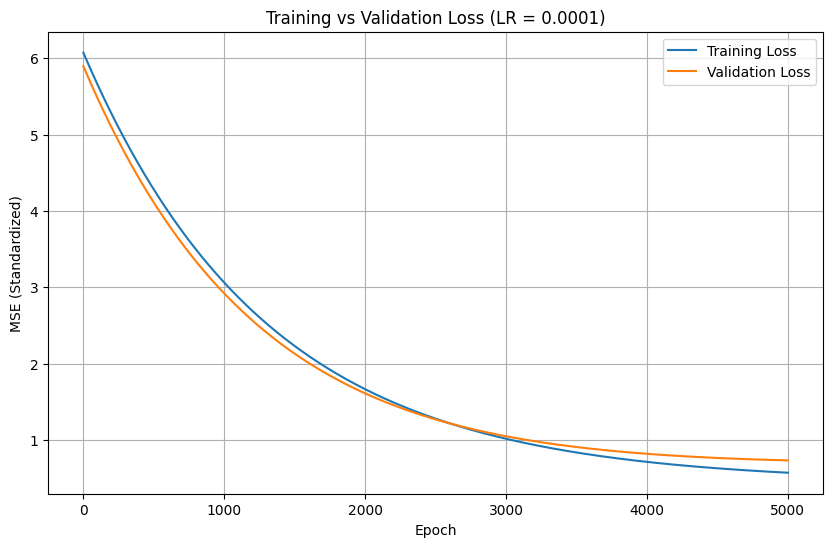

In [13]:
# Select best model based on final Validation Loss

best_lr = min(
    learningrates,
    key=lambda lr: loss_history_validation[lr][-1]
)

print("Best Learning Rate:", best_lr)
print("Final Training Loss:", loss_history_training[best_lr][-1])
print("Final Validation Loss:", loss_history_validation[best_lr][-1])
print("Final Validation R²:", R_sqr_history[best_lr][-1])


# Plot Training vs Validation Loss

plt.figure(figsize=(10, 6))

epochs = range(1, len(loss_history_training[best_lr]) + 1)

plt.plot(
    epochs,
    loss_history_training[best_lr],
    label="Training Loss"
)

plt.plot(
    epochs,
    loss_history_validation[best_lr],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (Standardized)")
plt.title(f"Training vs Validation Loss (LR = {best_lr})")
plt.legend()
plt.grid(True)

plt.show()

Problem c

In [14]:
# HW2: Convert cost function to MSE
hw2_val_cost = 1146360772862.6836
hw2_val_mse = 2 * hw2_val_cost

# Select best checkpoint across all learning rates

best_checkpoint_lr = min(
    best_checkpoints,
    key=lambda lr: best_checkpoints[lr]["val_loss"]
)

best_model = best_checkpoints[best_checkpoint_lr]

print("Best Learning Rate:", best_checkpoint_lr)
print("Best Epoch:", best_model["epoch"])
print("Best Validation MSE:", best_model["val_loss"])
print("Best Validation R²:", best_model["val_r2"])
print("Best Weights:", best_model["w"])
print("Best Bias:", best_model["b"])

# Compare best checkpoint with Homework 2
hw5_best_mse = best_model["val_loss"] * scaler_y.scale_[0]**2

improvement = (hw2_val_mse - hw5_best_mse) / hw2_val_mse * 100

print("HW2 Validation MSE:", hw2_val_mse)
print("HW5 Best Checkpoint MSE:", hw5_best_mse)
print(f"Improvement: {improvement:.2f}%")

Best Learning Rate: 0.01
Best Epoch: 66
Best Validation MSE: 0.7027944922447205
Best Validation R²: 0.571280837059021
Best Weights: [0.41375112533569336, 0.16269569098949432, 0.30287718772888184, 0.30994677543640137, 0.29162248969078064]
Best Bias: -1.0854561693918185e-08
HW2 Validation MSE: 2292721545725.367
HW5 Best Checkpoint MSE: 2166991180484.0361
Improvement: 5.48%


In [15]:
print("Best Learning Rate:", best_lr)
print("Best Parameters:", trained_params[best_lr])

Best Learning Rate: 0.0001
Best Parameters: ([0.457192987203598, 0.22968743741512299, 0.34470096230506897, 0.36343345046043396, 0.3582603633403778], -1.083032064030931e-08)
